In [30]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import pandas as pd
from matplotlib.colors import ListedColormap

In [48]:
iris = load_iris()
iris.feature_names
a=iris.DESCR

X_full = iris.data
y_full = iris.target
print(a)


.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

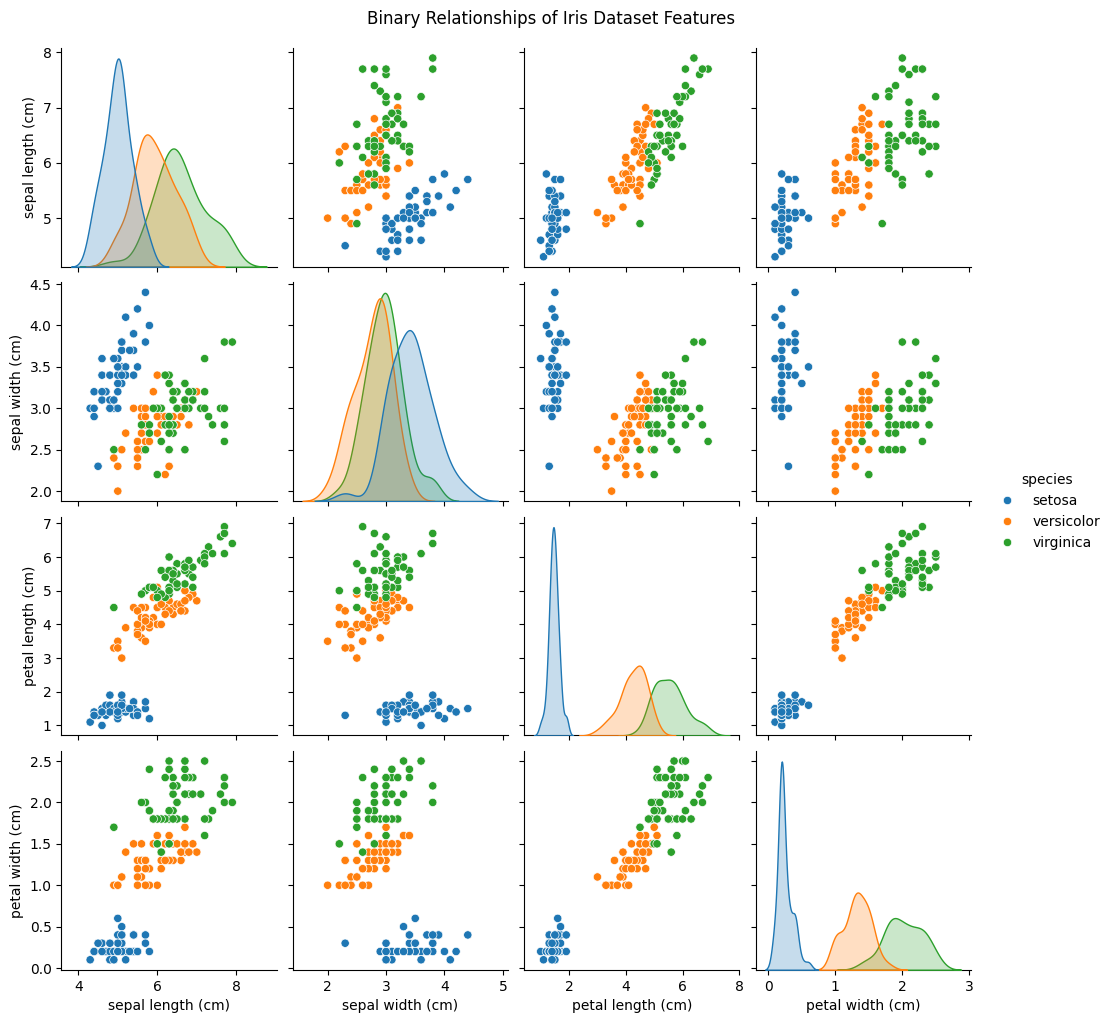

In [38]:
df_full_iris = pd.DataFrame(data=X_full, columns=iris.feature_names)
df_full_iris['species'] = iris.target_names[y_full]
sns.pairplot(df_full_iris, hue='species', diag_kind='kde')
plt.suptitle('Binary Relationships of Iris Dataset Features', y=1.02)
plt.show()

In [5]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [ ]:
X=X = iris.data[:, [2, 3]] 
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(f"Train set size: {X_train.shape}")
print(f"Test set size: {X_test.shape}")
print(f"Class distribution: {np.bincount(y)}")

Train set size: (105, 2)
Test set size: (45, 2)
Class distribution: [50 50 50]


In [50]:
class SingleLayerPerceptron:
    """
    Single Layer Perceptron (SLP) classifier using NumPy.

    Parameters
    ----------
    learning_rate : float
        Learning rate (between 0.0 and 1.0).
    n_iters : int
      Number of passes over the training dataset (epochs).
    random_state : int
      Random state for weight initialization to ensure reproducible results.
    """
    def __init__(self, learning_rate=0.01, n_iters=1000, random_state=1):
        self.learning_rate = learning_rate
        self.n_iters = n_iters
        self.random_state = random_state
        self.weights_ = None
        self.errors_ = []

    def fit(self, X, y):
        """
        Fit the model to the training data.

        Parameters
        ----------
        X : {array-like}, shape = [n_samples, n_features]
          Training vectors.
        y : array-like, shape = [n_samples]
          Target values.
        """
        # add bias term to input matrix
        X_b = np.c_[np.ones((len(X), 1)), X]
        
        # Randomly initialize weights
        rgen = np.random.RandomState(self.random_state)
        self.weights_ = rgen.normal(loc=0.0, scale=0.01, size=X_b.shape[1])
        self.errors_ = []

        for _ in range(self.n_iters):
            errors = 0
            for xi, target in zip(X_b, y):
                update = self.learning_rate * (target - self.predict(xi))
                self.weights_ += update * xi
                errors += int(update != 0.0)
            self.errors_.append(errors)
        return self

    def net_input(self, X):
        """Calculates net input."""
        # If a single sample is provided (like in fit), bias is already included.
        # If a multiple samples are provided, bias needs to be added.
        if X.ndim == 2:
             X_b = np.c_[np.ones((len(X), 1)), X]
             return np.dot(X_b, self.weights_)
        else: # Single sample
             return np.dot(X, self.weights_)

    def predict(self, X):
        """Makes a prediction (unit step function)."""
        return np.where(self.net_input(X) >= 0.0, 1, 0)

In [51]:
class SLP_OvR:
    """
    Single Layer Perceptron (SLP) classifier using One-vs-Rest (OvR) strategy.
    """
    def __init__(self, n_classes, learning_rate=0.01, n_iters=1000, random_state=1):
        self.n_classes = n_classes
        self.learning_rate = learning_rate
        self.n_iters = n_iters
        self.random_state = random_state
        # Create a list of perceptrons, one for each class
        self.perceptrons_ = [
            SingleLayerPerceptron(learning_rate=self.learning_rate, n_iters=self.n_iters, random_state=self.random_state)
            for _ in range(self.n_classes)
        ]

    def fit(self, X, y):
        """
        Train each perceptron in a one-vs-rest manner.

        For example, the perceptron for class 0 is trained to output 1
        when the target (y) is 0, and 0 otherwise.
        """
        for i in range(self.n_classes):
            # Make current class positive (1), others negative (0)
            y_ovr = np.where(y == i, 1, 0)
            print(f"\n{i}. Training Perceptron for class...")
            self.perceptrons_[i].fit(X, y_ovr)
        return self

    def predict(self, X):
        """
        Return the class of the perceptron with the highest activation value as the prediction.
        """
        # Get net input (activation) values from each perceptron
        activations = np.array([p.net_input(X) for p in self.perceptrons_])
        # Select the class with the highest activation (argmax)
        return np.argmax(activations, axis=0)

In [52]:
n_classes = len(np.unique(y))

# Create OvR model
slp_ovr_model = SLP_OvR(n_classes=n_classes, learning_rate=0.01, n_iters=100, random_state=42)

# Train the model
slp_ovr_model.fit(X_train, y_train)


0. Training Perceptron for class...

1. Training Perceptron for class...

2. Training Perceptron for class...


In [53]:
y_pred = slp_ovr_model.predict(X_test)

In [54]:
# evaluate results
accuracy = accuracy_score(y_test, y_pred)
print(f"\nModel Test Accuracy: {accuracy:.2f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred)) # [cite: 22]
print("\nConfusion Matrix:") # [cite: 22]
print(confusion_matrix(y_test, y_pred))


Model Test Accuracy: 0.60

Classification Report:
              precision    recall  f1-score   support

           0       0.45      1.00      0.62        15
           1       0.00      0.00      0.00        15
           2       1.00      0.80      0.89        15

    accuracy                           0.60        45
   macro avg       0.48      0.60      0.50        45
weighted avg       0.48      0.60      0.50        45


Confusion Matrix:
[[15  0  0]
 [15  0  0]
 [ 3  0 12]]


/home/bdere/anaconda3/envs/ML/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/bdere/anaconda3/envs/ML/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/bdere/anaconda3/envs/ML/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

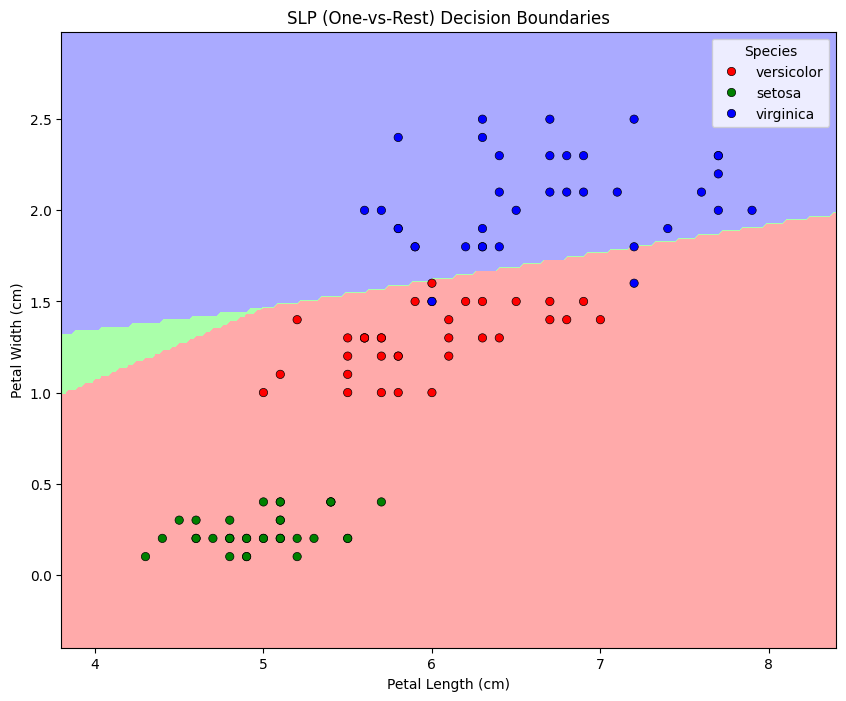

In [55]:
def plot_decision_boundary(X, y, model, title):
    """
    Visualize the decision boundaries of a classifier.
    """
    # Set color maps and markers
    cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
    cmap_bold = ['red', 'green', 'blue']

    # Set step size
    h = .02  # step size in the mesh

    # Find the min and max values of the features and leave some margin
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    # Create a mesh grid
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    # Make predictions for each point in the grid
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])

    # Reshape the result back to the grid shape
    Z = Z.reshape(xx.shape)

    # Plot the graph
    plt.figure(figsize=(10, 8))
    # Color the decision boundaries
    plt.contourf(xx, yy, Z, cmap=cmap_light)

    # Draw the training points on top
    sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=iris.target_names[y],
                    palette=cmap_bold, alpha=1.0, edgecolor="black")
    
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title(title)
    plt.xlabel('Petal Length (cm)')
    plt.ylabel('Petal Width (cm)')
    plt.legend(title='Species')
    plt.show()

# Call the function to plot the graph
plot_decision_boundary(X_train, y_train, slp_ovr_model, 
                       title='SLP (One-vs-Rest) Decision Boundaries')